# Augmented-decoy and NC Supplementary Figure 1 panels

In [1]:
from collections import OrderedDict
from functools import lru_cache
from pathlib import Path
import platform
import pickle

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance
from rdkit import Chem, RDLogger, rdBase
from rdkit.Chem import Crippen, Descriptors, Lipinski

RDLogger.DisableLog("rdApp.*")

TOP_K_VALUES = (200, 150, 100, 50)
PRIMARY_K = 100
MAX_K = max(TOP_K_VALUES)
TANIMOTO_THRESHOLD = 0.5


def locate_input_pickle():
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / "data" / "hariboss" / "hariboss_10fd_with_decoys.pkl"
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate data/hariboss/hariboss_10fd_with_decoys.pkl "
        "from the current working directory or its parents."
    )


INPUT_PATH = locate_input_pickle()
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)


def tanimoto_to_many(anchor_fp, other_fps):
    anchor = np.asarray(anchor_fp, dtype=np.int32)
    others = np.asarray(other_fps, dtype=np.int32)
    if others.ndim == 1:
        others = others[None, :]
    if anchor.ndim != 1 or others.ndim != 2 or others.shape[1] != anchor.shape[0]:
        raise ValueError("Fingerprint dimensions do not match")
    intersection = others @ anchor
    union = others.sum(axis=1, dtype=np.int32) + int(anchor.sum()) - intersection
    if np.any(union == 0):
        raise ValueError("Tanimoto similarity is undefined for an all-zero union")
    return intersection.astype(np.float64) / union


def pairwise_tanimoto(fp_matrix):
    fps = np.asarray(fp_matrix, dtype=np.int16)
    intersection = fps @ fps.T
    bit_counts = fps.sum(axis=1, dtype=np.int32)
    union = bit_counts[:, None] + bit_counts[None, :] - intersection
    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=np.float64),
        where=union > 0,
    )

def caption_stats(label, values):
    """
    Print the summary a figure caption quotes, so the numbers in the text
    are never retyped from a stale run.

    Reports n, mean +/- s.d. and median of `values` flattened. The s.d. is
    the population s.d. (ddof=0) of exactly the quantity the panel plots.
    """
    values = np.asarray(values, dtype=float).ravel()
    print(
        f"[caption] {label}\n"
        f"          n = {values.size:,}; "
        f"mean +/- s.d. = {values.mean():.3f} +/- {values.std():.3f}; "
        f"median = {np.median(values):.3f}; "
        f"range = {values.min():.3f}-{values.max():.3f}"
    )


In [2]:
with INPUT_PATH.open("rb") as handle:
    raw_data = pickle.load(handle)

ligands = OrderedDict()
source_record_count = 0
source_specific_similarity_blocks = []
threshold_violations = []
order_violations = []
repeat_mismatches = []

required_fields = {
    "ligand_id",
    "downloaded_ligand_smiles",
    "fp2",
    "decoy_smiles",
    "decoy_fp2",
}

for pdb_key, complexes in raw_data.items():
    for complex_key, record in complexes.items():
        source_record_count += 1
        missing = required_fields.difference(record)
        if missing:
            raise KeyError(f"{complex_key} is missing fields: {sorted(missing)}")

        ligand_id = record["ligand_id"]
        ligand_fp = np.asarray(record["fp2"], dtype=np.uint8)
        decoy_fp = np.asarray(record["decoy_fp2"], dtype=np.uint8)
        decoy_smiles = tuple(record["decoy_smiles"])

        if ligand_fp.shape != (1024,):
            raise ValueError(f"{complex_key}: ligand FP2 shape is {ligand_fp.shape}")
        if decoy_fp.ndim != 2 or decoy_fp.shape[1] != 1024:
            raise ValueError(f"{complex_key}: decoy FP2 shape is {decoy_fp.shape}")
        if len(decoy_smiles) != len(decoy_fp) or len(decoy_fp) < MAX_K:
            raise ValueError(f"{complex_key}: decoy SMILES/FP2 alignment or count is invalid")
        if not np.all((ligand_fp == 0) | (ligand_fp == 1)):
            raise ValueError(f"{complex_key}: ligand fingerprint is not binary")
        if not np.all((decoy_fp == 0) | (decoy_fp == 1)):
            raise ValueError(f"{complex_key}: decoy fingerprints are not binary")

        similarities = tanimoto_to_many(ligand_fp, decoy_fp)
        source_specific_similarity_blocks.append(similarities)

        for decoy_index in np.flatnonzero(similarities > TANIMOTO_THRESHOLD):
            threshold_violations.append(
                (
                    pdb_key,
                    complex_key,
                    ligand_id,
                    int(decoy_index),
                    float(similarities[decoy_index]),
                )
            )
        if np.any(np.diff(similarities) > 0):
            order_violations.append((pdb_key, complex_key, ligand_id))

        if ligand_id not in ligands:
            ligands[ligand_id] = {
                "ligand_id": ligand_id,
                "pdb_id": pdb_key,
                "complex_id": complex_key,
                "smiles": record["downloaded_ligand_smiles"],
                "fp": ligand_fp,
                "decoy_smiles": decoy_smiles,
                "decoy_fp": decoy_fp,
            }
        else:
            reference = ligands[ligand_id]
            if not (
                reference["smiles"] == record["downloaded_ligand_smiles"]
                and reference["decoy_smiles"] == decoy_smiles
                and np.array_equal(reference["fp"], ligand_fp)
                and np.array_equal(reference["decoy_fp"], decoy_fp)
            ):
                repeat_mismatches.append((ligand_id, complex_key))

all_source_specific_similarities = np.concatenate(source_specific_similarity_blocks)
del source_specific_similarity_blocks, raw_data

assert not repeat_mismatches, f"Repeated ligand IDs are inconsistent: {repeat_mismatches[:5]}"
assert not order_violations, f"Decoy lists are not sorted by decreasing similarity: {order_violations[:5]}"
assert not threshold_violations, f"Found ligand-specific FP2 similarities > 0.5: {threshold_violations[:5]}"

print(f"Source complexes audited:        {source_record_count:,}")
print(f"Unique ligand IDs retained:      {len(ligands):,}")
print(f"Ligand-specific pairs audited:   {len(all_source_specific_similarities):,}")
print(f"Pairs strictly above 0.5:        {len(threshold_violations):,}")
print(f"Pairs exactly equal to 0.5:      {np.count_nonzero(all_source_specific_similarities == 0.5):,}")
print(f"Maximum ligand-specific FP2 sim: {all_source_specific_similarities.max():.12f}")


Source complexes audited:        1,246
Unique ligand IDs retained:      311
Ligand-specific pairs audited:   249,200
Pairs strictly above 0.5:        0
Pairs exactly equal to 0.5:      8,809
Maximum ligand-specific FP2 sim: 0.500000000000


## FP2 similarity and top-k diversity analyses

In [3]:
ligand_ids = list(ligands)
n_ligands = len(ligand_ids)

# Similarity of every retained ligand to its own ordered top-200 decoys.
assigned_similarity = np.vstack(
    [tanimoto_to_many(data["fp"], data["decoy_fp"][:MAX_K]) for data in ligands.values()]
)
assert assigned_similarity.shape == (n_ligands, MAX_K)
assert assigned_similarity.max() <= TANIMOTO_THRESHOLD

average_assigned_similarity_by_topk = {
    top_k: assigned_similarity[:, :top_k].mean(axis=1) for top_k in TOP_K_VALUES
}

# One intra-decoy mean pairwise similarity per ligand at each top-k.
s_mean_by_topk = {top_k: np.empty(n_ligands, dtype=np.float64) for top_k in TOP_K_VALUES}
for ligand_index, data in enumerate(ligands.values()):
    full_pairwise = pairwise_tanimoto(data["decoy_fp"][:MAX_K])
    for top_k in TOP_K_VALUES:
        upper_triangle = np.triu_indices(top_k, k=1)
        s_mean_by_topk[top_k][ligand_index] = full_pairwise[:top_k, :top_k][upper_triangle].mean()

# Panel a uses the union of all top-100 raw decoy SMILES. A repeated SMILES must
# always map to the same stored FP2.
global_decoy_fp_by_smiles = OrderedDict()
for data in ligands.values():
    for smiles, fingerprint in zip(
        data["decoy_smiles"][:PRIMARY_K], data["decoy_fp"][:PRIMARY_K]
    ):
        if smiles in global_decoy_fp_by_smiles:
            if not np.array_equal(global_decoy_fp_by_smiles[smiles], fingerprint):
                raise ValueError(f"The same decoy SMILES maps to inconsistent FP2 values: {smiles}")
        else:
            global_decoy_fp_by_smiles[smiles] = fingerprint

ligand_fp_matrix = np.asarray([data["fp"] for data in ligands.values()], dtype=np.float32)
global_decoy_fp_matrix = np.asarray(list(global_decoy_fp_by_smiles.values()), dtype=np.float32)
global_intersection = ligand_fp_matrix @ global_decoy_fp_matrix.T
global_union = (
    ligand_fp_matrix.sum(axis=1)[:, None]
    + global_decoy_fp_matrix.sum(axis=1)[None, :]
    - global_intersection
)
global_similarity = global_intersection / global_union


## Physicochemical properties

In [4]:
PROPERTY_NAMES = ("MW", "LogP", "HBD", "HBA", "RotBonds")
PROPERTY_LABELS = {
    "MW": "Molecular Weight (MW)",
    "LogP": "cLogP",
    "HBD": "H-Bond Donors (HBD)",
    "HBA": "H-Bond Acceptors (HBA)",
    "RotBonds": "Rotatable Bonds",
}


@lru_cache(maxsize=None)
def molecular_properties(smiles):
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return None
    return {
        "MW": float(Descriptors.MolWt(molecule)),
        "LogP": float(Crippen.MolLogP(molecule)),
        "HBD": float(Lipinski.NumHDonors(molecule)),
        "HBA": float(Lipinski.NumHAcceptors(molecule)),
        "RotBonds": float(Lipinski.NumRotatableBonds(molecule)),
    }


# Pooled ligand-specific assignments for panel g.
property_values_by_topk = {
    top_k: {name: [] for name in PROPERTY_NAMES} for top_k in TOP_K_VALUES
}
invalid_decoy_smiles = set()
for data in ligands.values():
    for decoy_index, smiles in enumerate(data["decoy_smiles"][:MAX_K]):
        properties = molecular_properties(smiles)
        if properties is None:
            invalid_decoy_smiles.add(smiles)
            continue
        for top_k in TOP_K_VALUES:
            if decoy_index < top_k:
                for name in PROPERTY_NAMES:
                    property_values_by_topk[top_k][name].append(properties[name])

assert not invalid_decoy_smiles, f"RDKit-invalid decoys: {sorted(invalid_decoy_smiles)[:5]}"

# Unique top-200 raw decoy SMILES and unique ligand IDs for panel d.
unique_property_decoy_smiles = list(
    dict.fromkeys(
        smiles
        for data in ligands.values()
        for smiles in data["decoy_smiles"][:MAX_K]
    )
)

all_ligand_properties = {name: [] for name in PROPERTY_NAMES}
all_decoy_properties = {name: [] for name in PROPERTY_NAMES}
invalid_ligand_ids = []

for ligand_id, data in ligands.items():
    properties = molecular_properties(data["smiles"])
    if properties is None:
        invalid_ligand_ids.append(ligand_id)
        continue
    for name in PROPERTY_NAMES:
        all_ligand_properties[name].append(properties[name])

for smiles in unique_property_decoy_smiles:
    properties = molecular_properties(smiles)
    if properties is None:
        continue
    for name in PROPERTY_NAMES:
        all_decoy_properties[name].append(properties[name])

# These are the ranges used by the source figure. Exclusions are counted below.
PROPERTY_RANGES = {
    "MW": (50.0, 2000.0),
    "LogP": (-10.0, 15.0),
    "RotBonds": (0.0, 50.0),
}

filtered_ligand_properties = {}
filtered_decoy_properties = {}
property_exclusions = {}
for name in PROPERTY_NAMES:
    ligand_values = all_ligand_properties[name]
    decoy_values = all_decoy_properties[name]
    if name in PROPERTY_RANGES:
        lower, upper = PROPERTY_RANGES[name]
        filtered_ligand_properties[name] = [v for v in ligand_values if lower <= v <= upper]
        filtered_decoy_properties[name] = [v for v in decoy_values if lower <= v <= upper]
    else:
        filtered_ligand_properties[name] = list(ligand_values)
        filtered_decoy_properties[name] = list(decoy_values)
    property_exclusions[name] = (
        len(ligand_values) - len(filtered_ligand_properties[name]),
        len(decoy_values) - len(filtered_decoy_properties[name]),
    )


def discrete_js_divergence(left_values, right_values):
    combined = list(left_values) + list(right_values)
    minimum, maximum = int(min(combined)), int(max(combined))
    bins = np.arange(minimum - 0.5, maximum + 1.5, 1.0)
    left_hist, _ = np.histogram(left_values, bins=bins)
    right_hist, _ = np.histogram(right_values, bins=bins)
    return float(jensenshannon(left_hist / left_hist.sum(), right_hist / right_hist.sum()) ** 2)


global_wasserstein = {
    name: float(
        wasserstein_distance(
            filtered_ligand_properties[name], filtered_decoy_properties[name]
        )
    )
    for name in ("MW", "LogP")
}
global_jsd = {
    name: discrete_js_divergence(
        filtered_ligand_properties[name], filtered_decoy_properties[name]
    )
    for name in ("HBD", "HBA", "RotBonds")
}


## Figure panels

### Shared plotting style

In [5]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "axes.titlesize": 18,
        "axes.labelsize": 15,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
    }
)
plt.close("all")

topk_colors = {
    200: "steelblue",
    150: "salmon",
    100: "darkseagreen",
    50: "goldenrod",
}


def finish_axis(axis, grid=True):
    if grid:
        axis.grid(True, alpha=0.18, linewidth=0.8)
    else:
        axis.grid(False)
    axis.tick_params(direction="out")

### Panel a

[caption] (a) FP2 Tanimoto, 311 ligands x 13,699 unique augmented decoys
          n = 4,260,389; mean +/- s.d. = 0.171 +/- 0.084; median = 0.160; range = 0.000-1.000


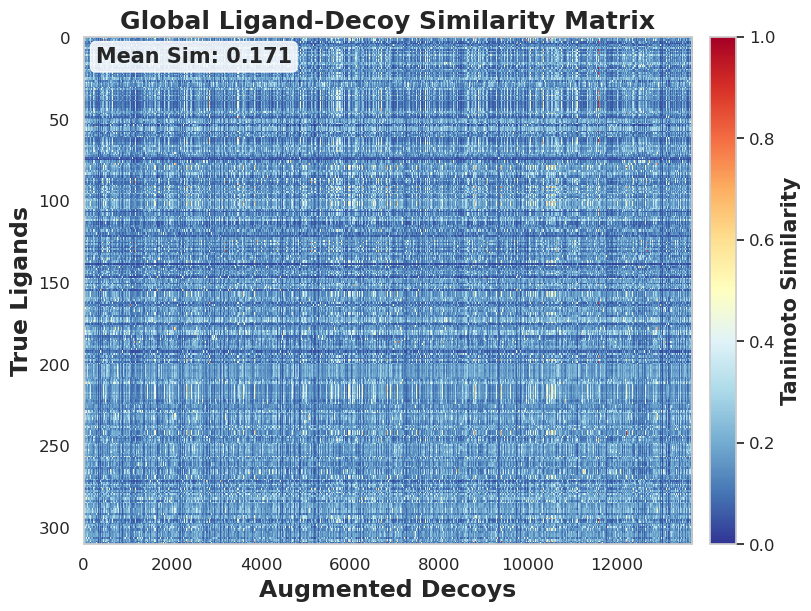

In [6]:
FIGDIR.mkdir(exist_ok=True)
DECOY_COLUMN_SHUFFLE_SEED = 0
column_order = np.random.default_rng(DECOY_COLUMN_SHUFFLE_SEED).permutation(
    global_similarity.shape[1]
)
shuffled_similarity = global_similarity[:, column_order]
assert np.isclose(shuffled_similarity.mean(), global_similarity.mean())

caption_stats(
    "(a) FP2 Tanimoto, "
    f"{global_similarity.shape[0]} ligands x "
    f"{global_similarity.shape[1]:,} unique augmented decoys",
    global_similarity,
)

fig_a, ax_a = plt.subplots(figsize=(8, 6), layout="constrained")

image = ax_a.imshow(
    shuffled_similarity,
    cmap="RdYlBu_r",
    aspect="auto",
    vmin=0,
    vmax=1,
    interpolation="nearest",
    rasterized=True,
)
ax_a.set_xlabel("Augmented Decoys", fontsize=17, fontweight="bold")
ax_a.set_ylabel("True Ligands", fontsize=17, fontweight="bold")
ax_a.set_title("Global Ligand-Decoy Similarity Matrix", fontsize=18, fontweight="bold")
ax_a.text(
    0.02,
    0.98,
    f"Mean Sim: {shuffled_similarity.mean():.3f}",
    transform=ax_a.transAxes,
    va="top",
    fontsize=15,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.85},
)
colorbar = fig_a.colorbar(image, ax=ax_a, fraction=0.046, pad=0.03)
colorbar.set_label("Tanimoto Similarity", fontsize=15, fontweight="bold")
finish_axis(ax_a, grid=False)

plt.savefig("figures/SupplementaryFig1a.png", dpi=300, bbox_inches='tight')
plt.show()

### Panel b

[caption] (b) true binder vs each of its top-100 ligand-specific decoys
          n = 31,100; mean +/- s.d. = 0.441 +/- 0.054; median = 0.458; range = 0.240-0.500
[caption] (b, alt) per-ligand average over its top-100 decoys
          n = 311; mean +/- s.d. = 0.441 +/- 0.049; median = 0.457; range = 0.287-0.498


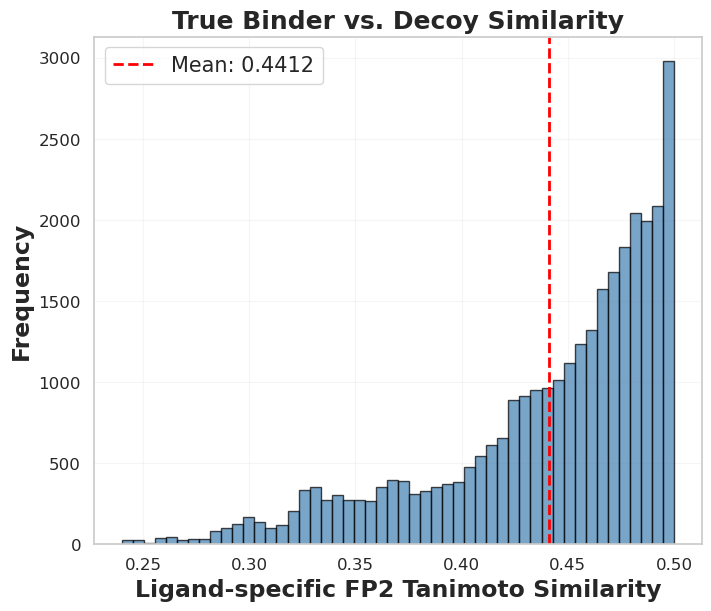

In [7]:
FIGDIR.mkdir(exist_ok=True)
# Panel b: true binder vs. its own top-100 decoys
fig_b, ax_b = plt.subplots(figsize=(7, 6), layout="constrained")

top100_assigned = assigned_similarity[:, :PRIMARY_K].ravel()
# Every ligand-decoy pair, not one average per ligand: the histogram has
# 311 x 100 entries. Both have mean 0.441, but the pooled s.d. is 0.054
# against 0.049 for the per-ligand averages, so the caption has to say
# which one it quotes. The per-ligand-average view is panel e.
caption_stats(
    f"(b) true binder vs each of its top-{PRIMARY_K} ligand-specific decoys",
    top100_assigned,
)
caption_stats(
    f"(b, alt) per-ligand average over its top-{PRIMARY_K} decoys",
    assigned_similarity[:, :PRIMARY_K].mean(axis=1),
)

ax_b.hist(top100_assigned, bins=50, color="steelblue", edgecolor="black", alpha=0.72)
ax_b.axvline(
    top100_assigned.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {top100_assigned.mean():.4f}",
)
ax_b.set_xlabel("Ligand-specific FP2 Tanimoto Similarity", fontsize=17, fontweight="bold")
ax_b.set_ylabel("Frequency", fontsize=17, fontweight="bold")
ax_b.set_title("True Binder vs. Decoy Similarity", fontsize=18, fontweight="bold")
ax_b.legend(loc="upper left", fontsize=15)
finish_axis(ax_b)
plt.savefig("figures/SupplementaryFig1b.png", dpi=300, bbox_inches='tight')

plt.show()

### Panel c

[caption] (c) intra-decoy mean pairwise similarity among each ligand's top-100 decoys
          n = 311; mean +/- s.d. = 0.419 +/- 0.067; median = 0.413; range = 0.267-0.752


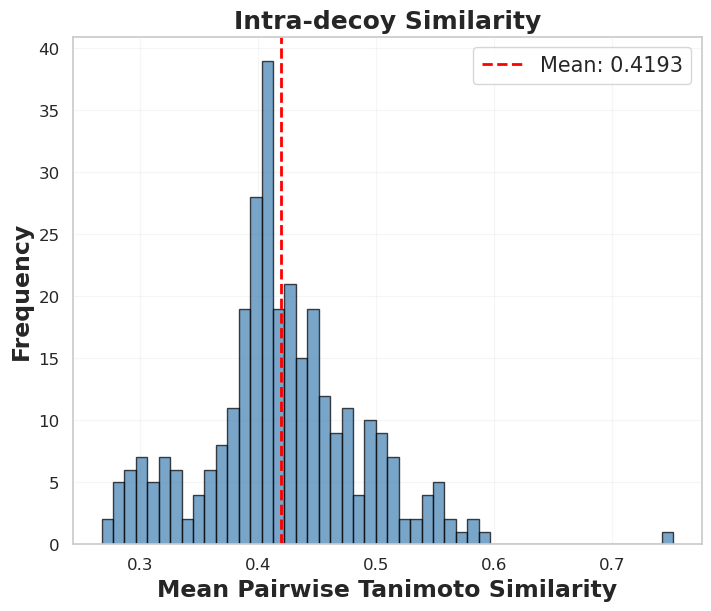

In [8]:
FIGDIR.mkdir(exist_ok=True)
# Panel c: intra-decoy similarity at top-100
fig_c, ax_c = plt.subplots(figsize=(7, 6), layout="constrained")

top100_s_mean = s_mean_by_topk[PRIMARY_K]
caption_stats(
    f"(c) intra-decoy mean pairwise similarity among each ligand's top-{PRIMARY_K} decoys",
    top100_s_mean,
)

ax_c.hist(top100_s_mean, bins=50, color="steelblue", edgecolor="black", alpha=0.72)
ax_c.axvline(
    top100_s_mean.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {top100_s_mean.mean():.4f}",
)
ax_c.set_xlabel("Mean Pairwise Tanimoto Similarity", fontsize=17, fontweight="bold")
ax_c.set_ylabel("Frequency", fontsize=17, fontweight="bold")
ax_c.set_title("Intra-decoy Similarity", fontsize=18, fontweight="bold")
ax_c.legend(loc="upper right", fontsize=15)
finish_axis(ax_c)
plt.savefig("figures/SupplementaryFig1c.png", dpi=300, bbox_inches='tight')

plt.show()

### Panel d

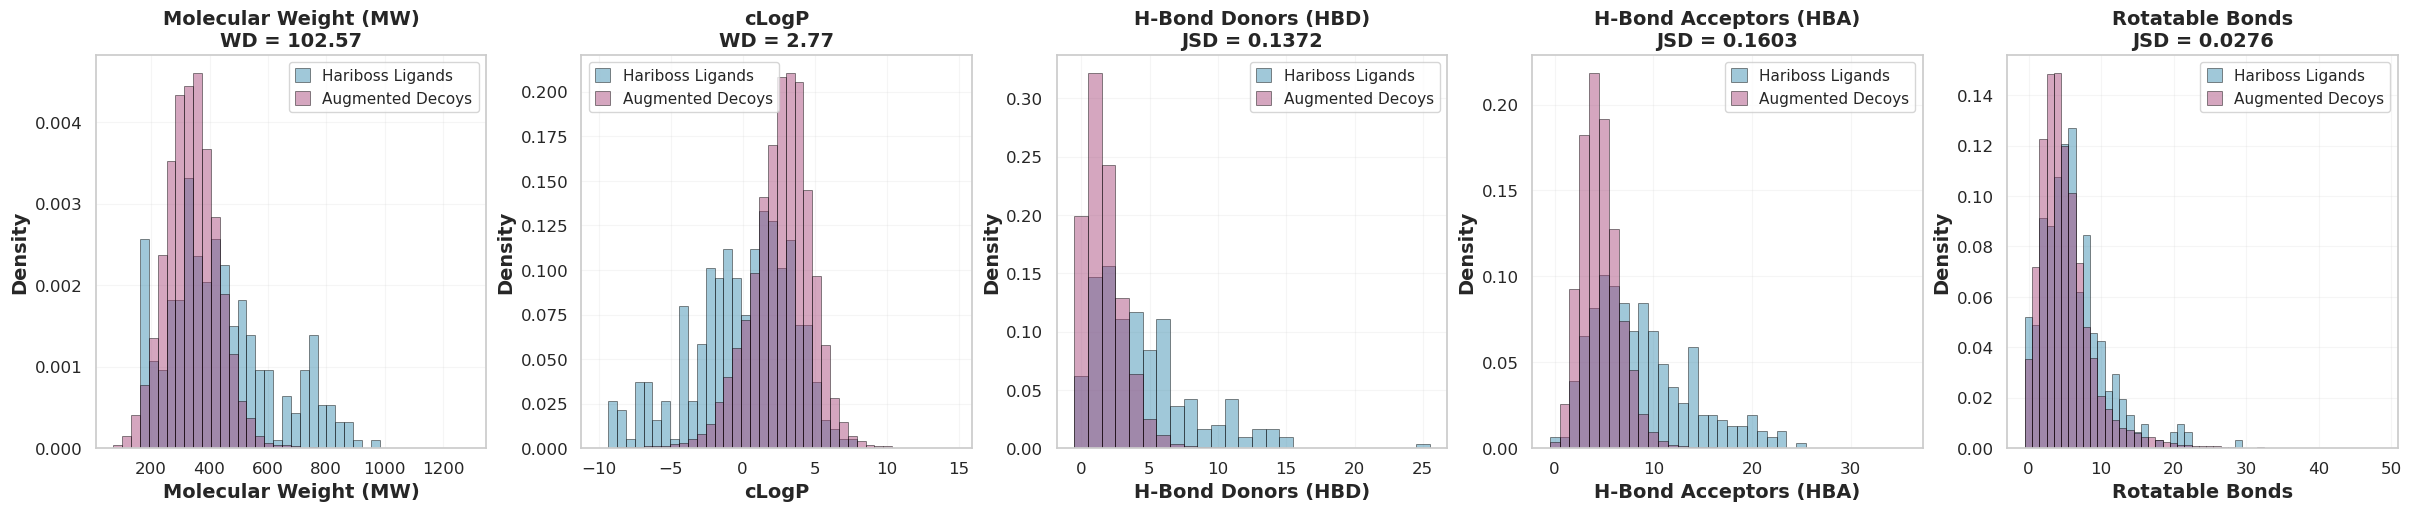

In [9]:
FIGDIR.mkdir(exist_ok=True)
# Panel d: physicochemical properties, ligands vs. unique top-200 decoys
fig_d, axes_d = plt.subplots(1, 5, figsize=(24, 5), layout="constrained")
ligand_color = "#2E86AB"
decoy_color = "#A23B72"

for axis, name in zip(axes_d, PROPERTY_NAMES):
    ligand_values = np.asarray(filtered_ligand_properties[name])
    decoy_values = np.asarray(filtered_decoy_properties[name])
    pooled = np.concatenate([ligand_values, decoy_values])
    if name in ("MW", "LogP"):
        bins = np.linspace(pooled.min(), pooled.max(), 41)
        metric_text = f"WD = {global_wasserstein[name]:.2f}"
    else:
        bins = np.arange(int(pooled.min()) - 0.5, int(pooled.max()) + 1.5, 1)
        metric_text = f"JSD = {global_jsd[name]:.4f}"
    axis.hist(
        ligand_values,
        bins=bins,
        density=True,
        color=ligand_color,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.45,
        label="Hariboss Ligands",
    )
    axis.hist(
        decoy_values,
        bins=bins,
        density=True,
        color=decoy_color,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.45,
        label="Augmented Decoys",
    )
    axis.set_xlabel(PROPERTY_LABELS[name], fontsize=14)
    axis.set_ylabel("Density", fontsize=14)
    axis.set_title(f"{PROPERTY_LABELS[name]}\n{metric_text}", fontsize=14)
    if name in ("LogP"):
        axis.legend(fontsize=11, loc="upper left", handlelength=1.0, handleheight=1.0)
    else:
        axis.legend(fontsize=11, loc="upper right", handlelength=1.0, handleheight=1.0)
    finish_axis(axis)

plt.savefig("figures/SupplementaryFig1d.png", dpi=300, bbox_inches='tight')
plt.show()

### Panel e

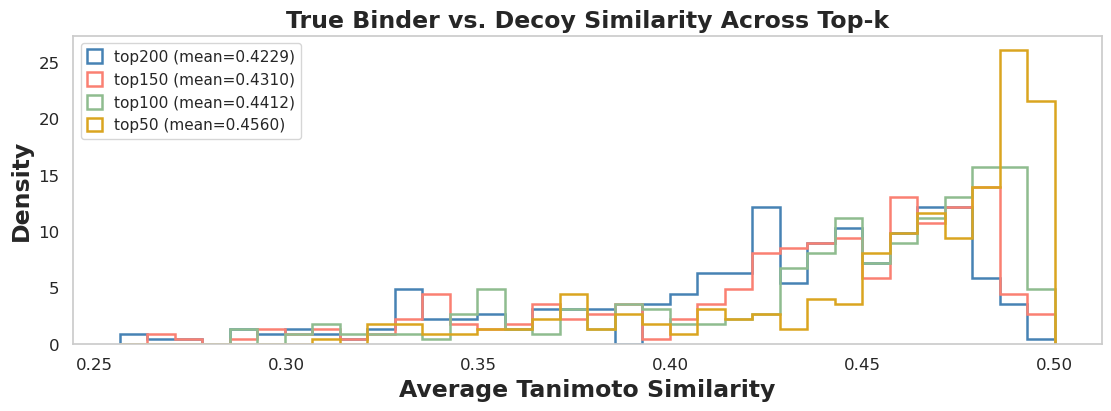

In [10]:
FIGDIR.mkdir(exist_ok=True)
# Panel e: ligand-decoy similarity across top-k
fig_e, ax_e = plt.subplots(figsize=(11, 4), layout="constrained")

average_bins = np.linspace(
    min(values.min() for values in average_assigned_similarity_by_topk.values()),
    max(values.max() for values in average_assigned_similarity_by_topk.values()),
    35,
)
for top_k in TOP_K_VALUES:
    values = average_assigned_similarity_by_topk[top_k]
    ax_e.hist(
        values,
        bins=average_bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=topk_colors[top_k],
        label=f"top{top_k} (mean={values.mean():.4f})",
    )
ax_e.set_xlabel("Average Tanimoto Similarity", fontsize=17, fontweight="bold")
ax_e.set_ylabel("Density", fontsize=17, fontweight="bold")
ax_e.set_title("True Binder vs. Decoy Similarity Across Top-k", fontsize=17, fontweight="bold")
ax_e.legend(loc="upper left", handlelength=1.0, handleheight=1.0)
finish_axis(ax_e, grid=False)

plt.savefig("figures/SupplementaryFig1e.png", dpi=300, bbox_inches='tight')
plt.show()

### Panel f

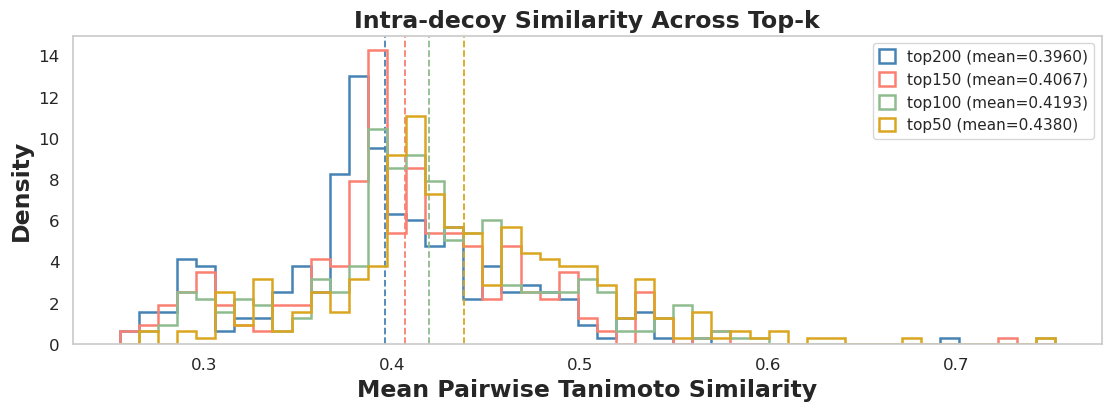

In [11]:
FIGDIR.mkdir(exist_ok=True)
# Panel f: intra-decoy similarity across top-k
fig_f, ax_f = plt.subplots(figsize=(11, 4), layout="constrained")

s_mean_bins = np.linspace(
    min(values.min() for values in s_mean_by_topk.values()),
    max(values.max() for values in s_mean_by_topk.values()),
    50,
)
for top_k in TOP_K_VALUES:
    values = s_mean_by_topk[top_k]
    ax_f.hist(
        values,
        bins=s_mean_bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=topk_colors[top_k],
        label=f"top{top_k} (mean={values.mean():.4f})",
    )
    ax_f.axvline(values.mean(), color=topk_colors[top_k], linestyle="--", linewidth=1.3)
ax_f.set_xlabel("Mean Pairwise Tanimoto Similarity", fontsize=17, fontweight="bold")
ax_f.set_ylabel("Density", fontsize=17, fontweight="bold")
ax_f.set_title("Intra-decoy Similarity Across Top-k", fontsize=17, fontweight="bold")
ax_f.legend(loc="upper right", handlelength=1.0, handleheight=1.0)
finish_axis(ax_f, grid=False)

plt.savefig("figures/SupplementaryFig1f.png", dpi=300, bbox_inches='tight')
plt.show()

### Panel g

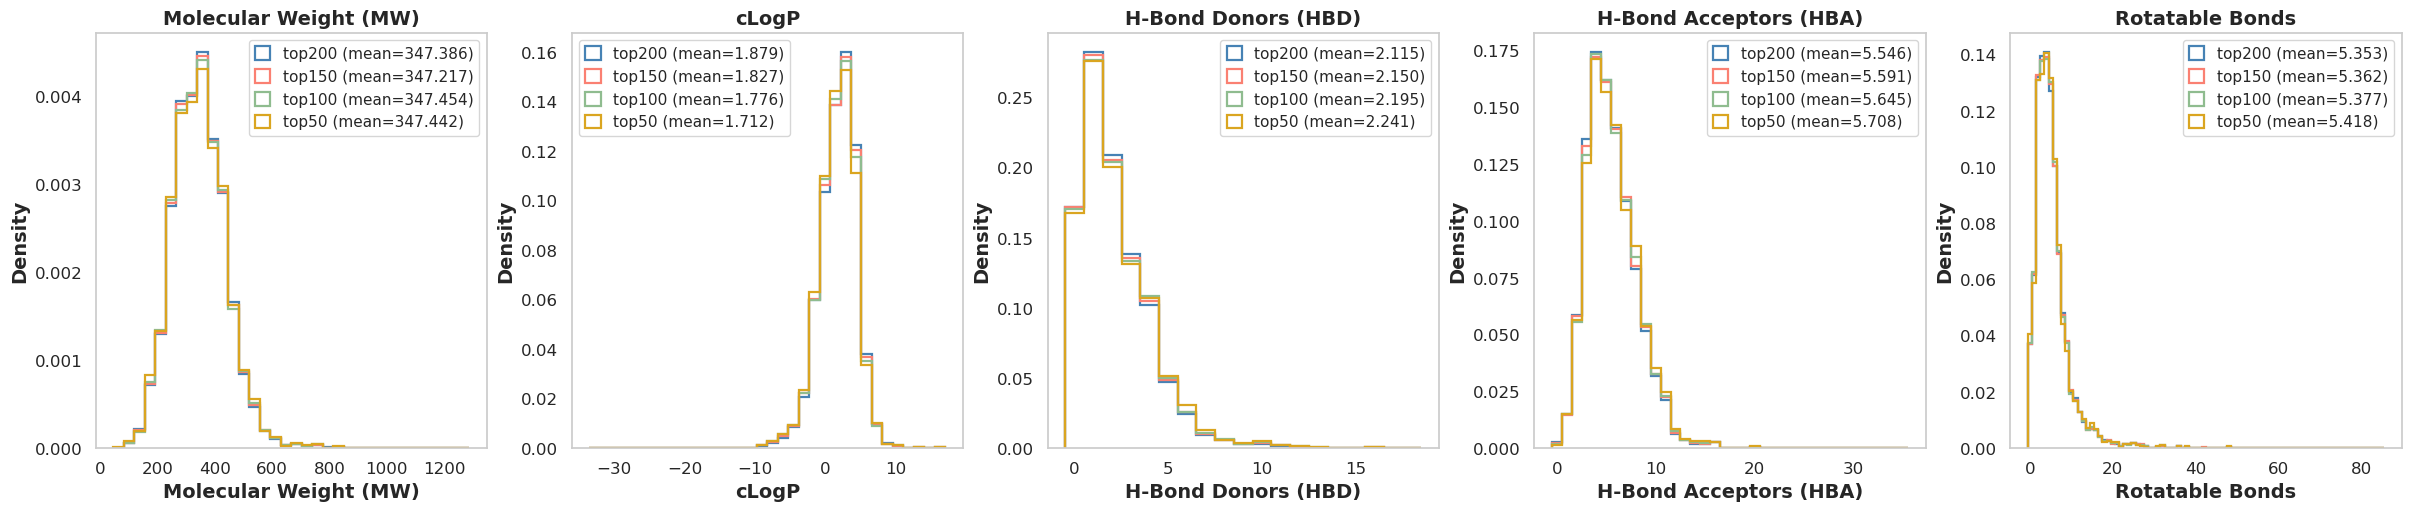

In [12]:
FIGDIR.mkdir(exist_ok=True)
# Panel g: pooled decoy properties across top-k
fig_g, axes_g = plt.subplots(1, 5, figsize=(24, 5), layout="constrained")

for axis, name in zip(axes_g, PROPERTY_NAMES):
    values_by_k = {
        top_k: np.asarray(property_values_by_topk[top_k][name])
        for top_k in TOP_K_VALUES
    }
    pooled = np.concatenate(list(values_by_k.values()))
    if name in ("MW", "LogP"):
        bins = np.linspace(pooled.min(), pooled.max(), 35)
    else:
        bins = np.arange(int(pooled.min()) - 0.5, int(pooled.max()) + 1.5, 1)
    for top_k in TOP_K_VALUES:
        values = values_by_k[top_k]
        axis.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.6,
            color=topk_colors[top_k],
            label=f"top{top_k} (mean={values.mean():.3f})",
        )
    axis.set_xlabel(PROPERTY_LABELS[name], fontsize=14)
    axis.set_ylabel("Density", fontsize=14)
    axis.set_title(PROPERTY_LABELS[name], fontsize=14)

    if name in ("LogP"):
        axis.legend(fontsize=11, loc="upper left", handlelength=1.0, handleheight=1.0)
    else:
        axis.legend(fontsize=11, loc="upper right", handlelength=1.0, handleheight=1.0)
    finish_axis(axis, grid=False)

plt.savefig("figures/SupplementaryFig1g.png", dpi=300, bbox_inches='tight')
plt.show()

## Self-check against the shipped Source Data


In [13]:
# --- Self-check against the shipped Source Data -------------------------------
# Every quantity plotted above is compared with raw_data/SupplementaryFig1/*_summary.csv,
# so a stale notebook cannot disagree silently with the submitted Source Data.

import csv


def find_raw_data():
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / "raw_data" / "SupplementaryFig1"
        if candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate raw_data/SupplementaryFig1 from the current working "
        "directory or its parents."
    )


RAW_DATA_DIR = find_raw_data()
TOLERANCE = 6e-5  # the tables store four decimal places
checks = []


def read_summary(name):
    with (RAW_DATA_DIR / name).open() as handle:
        return list(csv.DictReader(handle))


def check(label, computed, expected, tolerance=TOLERANCE):
    computed, expected = float(computed), float(expected)
    checks.append((abs(computed - expected) <= tolerance, label, computed, expected))


def check_distribution(label, values, row):
    values = np.asarray(values, dtype=np.float64).ravel()
    check(f"{label} n", values.size, row["n"], 0)
    check(f"{label} mean", values.mean(), row["mean"])
    check(f"{label} s.d.", values.std(), row["sd_population_ddof0"])
    check(f"{label} median", np.median(values), row["median"])
    check(f"{label} min", values.min(), row["min"])
    check(f"{label} max", values.max(), row["max"])


# a - every ligand against the union of all top-100 decoys
check_distribution("1a", global_similarity, read_summary("SupplementaryFig1a_summary.csv")[0])

# b - every ligand against its own top-100 decoys
check_distribution(
    "1b", assigned_similarity[:, :PRIMARY_K], read_summary("SupplementaryFig1b_summary.csv")[0]
)

# c - intra-decoy mean pairwise similarity at top-100
check_distribution(
    "1c", s_mean_by_topk[PRIMARY_K], read_summary("SupplementaryFig1c_summary.csv")[0]
)

# d - physicochemical properties, ligands against the pooled unique decoys
CSV_PROPERTY_NAME = {"MW": "MW", "LogP": "cLogP", "HBD": "HBD", "HBA": "HBA", "RotBonds": "RotBonds"}
statistic_by_property = dict(global_wasserstein, **global_jsd)
for row in read_summary("SupplementaryFig1d_physicochemical_properties_summary.csv"):
    name = next(k for k, v in CSV_PROPERTY_NAME.items() if v == row["property"])
    tag = f"1d {row['property']}"
    ligand_values = np.asarray(filtered_ligand_properties[name], dtype=np.float64)
    decoy_values = np.asarray(filtered_decoy_properties[name], dtype=np.float64)
    check(f"{tag} n_ligands", ligand_values.size, row["n_ligands"], 0)
    check(f"{tag} ligand mean", ligand_values.mean(), row["ligand_mean"])
    check(f"{tag} ligand s.d.", ligand_values.std(), row["ligand_sd_ddof0"])
    check(f"{tag} ligand median", np.median(ligand_values), row["ligand_median"])
    check(f"{tag} decoy mean", decoy_values.mean(), row["decoy_mean"])
    check(f"{tag} decoy s.d.", decoy_values.std(), row["decoy_sd_ddof0"])
    check(f"{tag} decoy median", np.median(decoy_values), row["decoy_median"])
    check(f"{tag} {row['statistic']}", statistic_by_property[name], row["statistic_value"])

# e - ligand-to-own-decoy similarity by top-k
for row in read_summary("SupplementaryFig1e_summary.csv"):
    top_k = int(row["top_k"])
    check_distribution(f"1e k={top_k}", average_assigned_similarity_by_topk[top_k], row)

# f - intra-decoy mean pairwise similarity by top-k
for row in read_summary("SupplementaryFig1f_summary.csv"):
    top_k = int(row["top_k"])
    check_distribution(f"1f k={top_k}", s_mean_by_topk[top_k], row)

# g - pooled decoy properties by top-k
for row in read_summary("SupplementaryFig1g_summary.csv"):
    top_k = int(row["top_k"])
    name = next(k for k, v in CSV_PROPERTY_NAME.items() if v == row["property"])
    tag = f"1g {row['property']} k={top_k}"
    values = np.asarray(property_values_by_topk[top_k][name], dtype=np.float64)
    check(f"{tag} n", values.size, row["n"], 0)
    check(f"{tag} mean", values.mean(), row["mean"])
    check(f"{tag} s.d.", values.std(), row["sd_ddof0"])
    check(f"{tag} median", np.median(values), row["median"])
    check(f"{tag} min", values.min(), row["min"])
    check(f"{tag} max", values.max(), row["max"])

failures = [c for c in checks if not c[0]]
for _, label, computed, expected in failures:
    print(f"MISMATCH  {label}: notebook {computed!r} vs Source Data {expected!r}")
print(f"{len(checks) - len(failures)}/{len(checks)} values match {RAW_DATA_DIR}")
assert not failures, f"{len(failures)} value(s) disagree with the shipped Source Data"


226/226 values match /path/to/SMARTBind/raw_data/SupplementaryFig1
